In [1]:
%reload_ext autoreload
%autoreload 2

import warnings, os, sys, re
sys.setrecursionlimit(1000000)
warnings.filterwarnings('ignore')
from IPython.display import clear_output

import numpy as np
import pandas as pd
from functools import reduce
from tqdm.auto import tqdm
import swifter

from rdkit import Chem
from rdkit.Chem import PandasTools
PandasTools.RenderImagesInAllDataFrames(images=True)
from rdkit import RDLogger; RDLogger.DisableLog('rdApp.*')
from rdkit.DataStructs import TanimotoSimilarity
from rdkit.Chem.AllChem import GetMorganFingerprintAsBitVect
from rdkit.Chem import Descriptors
from rdkit import DataStructs

from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.ipython_useSVG = True
IPythonConsole.molSize = 600, 400
IPythonConsole.drawOptions.addAtomIndices = False

import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
pio.renderers.default = "notebook"
pio.renderers.default_config = {
    "toImageButtonOptions": {"format": "png", "scale": 5}}

sys.path.append(os.path.abspath(R"C:\\Users\\Idener\\Sync\\CODE"))
from aiddtools import fingerprint_tools as fpt
clear_output()

## OLD

In [ ]:
df_cpd = pd.read_csv('../data/Database_KEGG_cpd.csv')
df_cpd = df_cpd.iloc[20:].dropna(subset=['FORMULA', 'INCHI', 'REACTION'])
df_cpd = df_cpd[df_cpd['MOL_WEIGHT'] > 50]

allowed_elements = R'(C|H|N|O|F|Cl|Br|P|S)'
pattern = rf'^({allowed_elements}[0-9]*)+$'
df_cpd = df_cpd[
    df_cpd['FORMULA'].str.fullmatch(pattern, case=False, na=False) &
    df_cpd['FORMULA'].str.contains('C', case=False, na=False) &
    df_cpd['FORMULA'].str.contains('H', case=False, na=False)]

df_cpd

In [ ]:
db_folder = R"C:\Users\Idener\Sync\CODE\fantastic-biofragmenter\data"
df_pairs = pd.read_parquet(Rf"{db_folder}\Database_KEGG_rn.gzip", engine='fastparquet')
df_pairs = df_pairs.explode('RPAIR')
df_pairs['RPAIR'] = df_pairs['RPAIR'].apply(lambda x: x.split('_'))
df_pairs['RPAIR'] = df_pairs['RPAIR'].apply(lambda x: [df_cpd.loc[df_cpd['ENTRY'] == r, 'ISOSMILES'].values[0]
                                                 if not df_cpd.loc[df_cpd['ENTRY'] == r, 'ISOSMILES'].empty
                                                 else None for r in x])
df_pairs = df_pairs[df_pairs['RPAIR'].apply(lambda x: all(x))]

df_pairs[['RPAIR_1', 'RPAIR_2']] = pd.DataFrame(df_pairs['RPAIR'].tolist(), index=df_pairs.index)
PandasTools.AddMoleculeColumnToFrame(df_pairs, smilesCol='Reactant', molCol='ROMOL_1')
PandasTools.AddMoleculeColumnToFrame(df_pairs, smilesCol='Product', molCol='ROMOL_2')
df_pairs = df_pairs.dropna(subset=['ROMOL_1', 'ROMOL_2'])

df_pairs['ATOMS_R'] = df_pairs['ROMOL_1'].apply(lambda x: x.GetNumHeavyAtoms() if x else None)
df_pairs['Product_ATOMS'] = df_pairs['ROMOL_2'].apply(lambda x: x.GetNumHeavyAtoms() if x else None)
df_pairs['ATOM_DIFF'] = abs(df_pairs['ATOMS_R'] - df_pairs['Product_ATOMS'])
df_pairs = df_pairs[df_pairs['ATOM_DIFF'] <= 5]

df_pairs = df_pairs[['REACTION', 'EQUATION', 'BRITE', 'Reactant', 'Product', 'ATOM_DIFF', 'ROMOL_1', 'ROMOL_2']]

In [ ]:
methods = ['maccs', 'rdkit', 'morgan2', 'morgan3', 'avalon', 'torsion', 'mhfp', 'mhfp6']

for method in methods:
    df_pairs['FP_1'] = df_pairs['ROMOL_1'].apply(lambda mol: calculate_fp(mol, method=method))
    df_pairs['FP_2'] = df_pairs['ROMOL_2'].apply(lambda mol: calculate_fp(mol, method=method))
    df_pairs[f'similarity_{method}'] = df_pairs.apply(lambda row: get_similarity(row['FP_1'], row['FP_2'], method=method), axis=1)

df_pairs.drop(columns=['FP_1', 'FP_2', 'ROMOL_1', 'ROMOL_2']).to_csv(R"C:\Users\Idener\Desktop\KEGG_RPAIRS.csv", index=False)
df_pairs

In [ ]:
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

bin_edges = np.arange(0, 1.1, 0.1)
bin_labels = [f"{round(bin_edges[i], 1)}–{round(bin_edges[i+1], 1)}" for i in range(len(bin_edges)-1)][::-1]

# Determine number of rows and columns for subplots (2x3 grid here)
rows = 2
cols = 4

# Calculate counts for all methods first to find the global max
all_counts = []
for method in methods:
    df_1 = df_pairs.copy().dropna(subset=['BRITE'])
    df_1 = df_1[df_1['BRITE'].str.contains('5. Isomerase reactions')]
    similarities = df_1[f'similarity_{method}'].dropna()
    counts, _ = np.histogram(similarities, bins=bin_edges)
    counts = counts[::-1]  # reverse to match reversed x-axis
    all_counts.append(counts)
max_count = max([max(counts) for counts in all_counts])

fig = make_subplots(rows=rows, cols=cols, subplot_titles=[m.upper() for m in methods])

for i, method in enumerate(methods):
    row = i // cols + 1
    col = i % cols + 1

    counts = all_counts[i]

    fig.add_trace(
        go.Bar(x=bin_labels, y=counts, name=method.upper(), showlegend=False),
        row=row, col=col
    )

    fig.update_xaxes(title_text="Similarity", categoryorder='array', categoryarray=bin_labels, row=row, col=col)
    fig.update_yaxes(title_text="Count", range=[0, max_count], row=row, col=col)  # same y-axis max

fig.update_layout(
    title="Similarity Distributions per Fingerprint Method",
    height=600,
    width=1000,
    template="plotly_white"
)

fig.show()

In [ ]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# Define thresholds
thresholds = np.arange(0.0, 1.01, 0.05)

# Collect correlation data
results = {method: {'thresholds': [], 'pearson': [], 'spearman': []} for method in methods}

for method in methods:
    for threshold in thresholds:
        subdf = df_pairs[df_pairs[f'similarity_{method}'] >= threshold].dropna(subset=['ATOM_DIFF'])
        if subdf.shape[0] >= 5:
            corr_pearson = subdf[[f'similarity_{method}', 'ATOM_DIFF']].corr(method='pearson').iloc[0, 1]
            corr_spearman = subdf[[f'similarity_{method}', 'ATOM_DIFF']].corr(method='spearman').iloc[0, 1]
        else:
            corr_pearson = np.nan
            corr_spearman = np.nan

        results[method]['thresholds'].append(threshold)
        results[method]['pearson'].append(abs(corr_pearson))
        results[method]['spearman'].append(abs(corr_spearman))

# --- Pearson Plot ---
fig_pearson = go.Figure()
for method in methods:
    fig_pearson.add_trace(go.Scatter(
        x=results[method]['thresholds'],
        y=results[method]['pearson'],
        mode='lines+markers',
        name=method.upper()
    ))

fig_pearson.update_layout(
    title='|Pearson Correlation| vs Similarity Threshold',
    xaxis_title='Similarity Threshold (Descending)',
    yaxis_title='|Pearson r|',
    xaxis=dict(autorange='reversed'),
    template='plotly_white',
    width=900,
    height=500
)

# --- Spearman Plot ---
fig_spearman = go.Figure()
for method in methods:
    fig_spearman.add_trace(go.Scatter(
        x=results[method]['thresholds'],
        y=results[method]['spearman'],
        mode='lines+markers',
        name=method.upper()
    ))

fig_spearman.update_layout(
    title='|Spearman Correlation| vs Similarity Threshold',
    xaxis_title='Similarity Threshold (Descending)',
    yaxis_title='|Spearman ρ|',
    xaxis=dict(autorange='reversed'),
    template='plotly_white',
    width=900,
    height=500
)

# Show both plots
fig_pearson.show()
fig_spearman.show()


In [ ]:
from skfp.fingerprints import MACCSFingerprint, PubChemFingerprint

smiles_list = ["O=S(=O)(O)CCS(=O)(=O)O", "O=C(O)c1ccccc1O"]
mols = [Chem.MolFromSmiles(smiles) for smiles in smiles_list]


# fp_maccs = MACCSFingerprint(n_jobs=-1)
# fp_maccs_count = MACCSFingerprint(count=True, n_jobs=-1)

fp_pubchem = PubChemFingerprint(n_jobs=-1)
fp_pubchem_count = PubChemFingerprint(count=True, n_jobs=-1)

# X_maccs = fp_maccs.transform(mols)
# X_maccs_count = fp_maccs_count.transform(mols)

X_pubchem = fp_pubchem.transform(mols)
# X_pubchem_count = fp_pubchem_count.transform(mols)
X_pubchem

In [ ]:
sys.path.append(os.path.abspath("C:\\Users\\Idener\\Documents\\MEGA\\drug_design_modules\\NC-MFP"))

from itertools import chain
from NC_MFP_Algorithm.Preprocessing_step import Preprocessing
from NC_MFP_Algorithm.Scaffold_matching_step import Scaffold_Matching
from NC_MFP_Algorithm.Fragment_list_generation_step import Fragment_List_Generation
from NC_MFP_Algorithm.SFCP_assigning_step import SFCP_Assigning
from NC_MFP_Algorithm.Fragment_identifying_step import Fragment_identifying
from NC_MFP_Algorithm.Fingerprint_representation_step import Fingerprint_representation

# Define classes
Step_1 = Preprocessing()
Step_2 = Scaffold_Matching()
Step_3 = Fragment_List_Generation()
Step_4 = SFCP_Assigning()
Step_5 = Fragment_identifying()
Step_6 = Fingerprint_representation()

All_Scaffold_FilePath = ('C:\\Users\\Idener\\Documents\\MEGA\\drug_design_modules\\NC-MFP\\Data\\All_Optimized_Scaffold_List.txt')

# qMols_Smarts = Step_1.get_Query_Mols_Smarts(Query_FilePath)
qMols_Smarts = df_pairs['ROMOL_1'].apply(Chem.MolToSmarts).dropna().tolist()[:500]

Final_all_Fragment_List = []
for qMol_Smart in qMols_Smarts:
    fragments = Step_3.generate_all_Fragment_List(All_Scaffold_FilePath, qMol_Smart) or [qMol_Smart]
    Final_all_Fragment_List.append(fragments)
Final_all_Fragment_List = list(set(chain.from_iterable(Final_all_Fragment_List)))
Final_all_Fragment_Dic = Step_3.generate_all_Fragment_Dictionary(Final_all_Fragment_List)

Final_all_NC_MFP_Info = []
for smarts in tqdm(qMols_Smarts):
    # Step 2: Scaffold matching
    scaffold_matches = Step_2.match_All_Scaffold_Smarts(All_Scaffold_FilePath, smarts)
    scaffold_matches = list(set(scaffold_matches))  # Deduplicate

    # Step 4: Scaffold-Fragment Connection Pairs (SFCP)
    sfcp_list = Step_4.assign_all_sfcp_smarts(All_Scaffold_FilePath, smarts)

    # Step 5: Fragment identification
    try:
        fragment_list = Step_5.identify_Fragment_Smarts(All_Scaffold_FilePath, smarts, Final_all_Fragment_Dic)
    except: pass

    # Merge NC-MFP info
    merged_info = scaffold_matches + sfcp_list + fragment_list
    Final_all_NC_MFP_Info.append(merged_info)


# [6] Fingerprint representation step #
# Get all NC-MFP label
Final_all_NC_MFP_Label = Step_6.get_all_NC_MFP_Label(Final_all_NC_MFP_Info)

# Get all NC-MFP Bit String
Final_Bitstring = Step_6.get_qMol_NC_MFP_Value_Idx(Final_all_NC_MFP_Info, Final_all_NC_MFP_Label)
print(Final_Bitstring)

# NEW APPROACH

,Reactant,Product,ROMol_R,ROMol_P,Feature_vec_R,Feature_vec_P
0,CC(=O)C(=O)O,CC(=O)C(C)(O)C(=O)O,,,"[0, 0, 0, 0, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 5, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
1,O=CC(=O)O,O=CC(O)C(=O)O,,,"[0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
2,Cc1ncc(C[n+]2csc(CCOP(=O)(O)OP(=O)(O)O)c2C)c(N)n1,Cc1ncc(C[n+]2c(C(C)O)sc(CCOP(=O)(O)OP(=O)(O)O)...,,,"[2, 2, 0, 7, 5, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, ...","[2, 2, 0, 7, 7, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, ..."
3,NCCCCN,NCCCCNCCCCN,,,"[0, 0, 0, 0, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 8, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
4,N[CH](CCC(=O)O)C(=O)O,O=C(O)CCC(=O)C(=O)O,,,"[0, 0, 0, 0, 5, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 5, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
...,...,...,...,...,...,...
19292,CC(C)=CCC/C(C)=C/COP(=O)(O)OP(=O)(O)OP(=O)(O)O,CC(C)=CCC/C(C)=C/COP(=O)(O)OP(=O)(O)O,,,"[0, 0, 0, 0, 10, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0,...","[0, 0, 0, 0, 10, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0,..."
19293,CC(C)=CCCC(C)=CCCC(C)=CCCC(C)=CCOP(=O)(O)OP(=O...,CC(C)=CCCC(C)=CCCC(C)=CCCC(C)=CCOP(=O)(O)OP(=O...,,,"[0, 0, 0, 0, 20, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0,...","[0, 0, 0, 0, 20, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0,..."
19294,CC(C)=CCCC(C)=CCCC(C)=CCCC(C)=CCOP(=O)(O)OP(=O...,CC(C)=CCCC(C)=CCCC(C)=CCCC(C)=CCOP(=O)(O)OP(=O...,,,"[0, 0, 0, 0, 20, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0,...","[0, 0, 0, 0, 20, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0,..."
19295,CCC(C)CO,CCC(C)C=O,,,"[0, 0, 0, 0, 5, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 5, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."

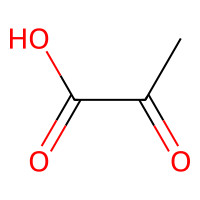
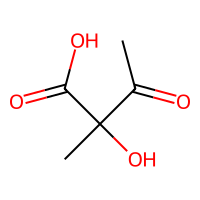
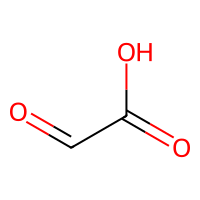
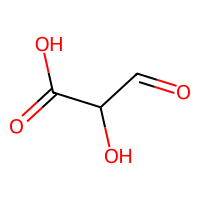
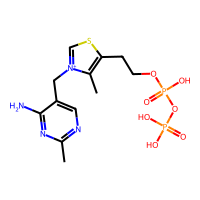
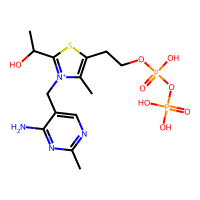
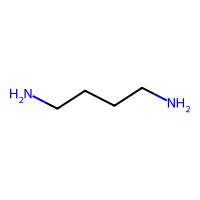
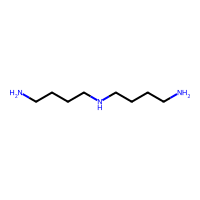
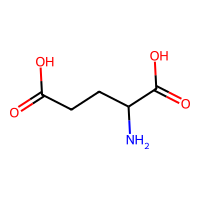
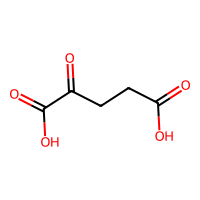
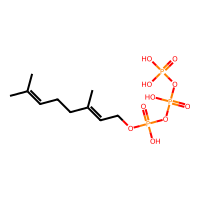
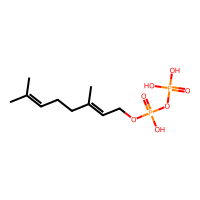
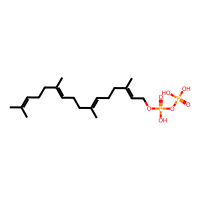
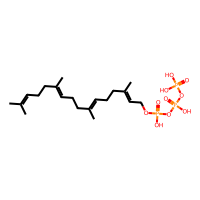
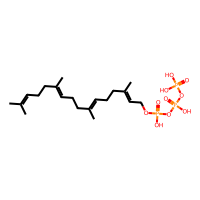
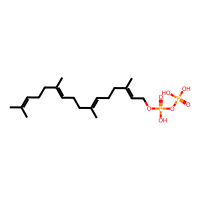
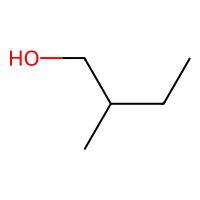
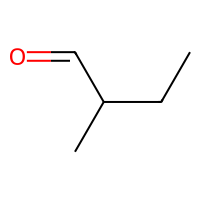
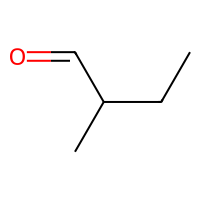
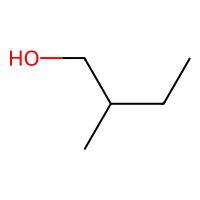

In [7]:
pd.read_pickle('../classifier/Database_reaction_pairs.pkl')


=== Mean performance across folds ===
accuracy            : 0.968
precision_macro     : 0.941
recall_macro        : 0.944
f1_macro            : 0.942
precision_weighted  : 0.969
recall_weighted     : 0.968
f1_weighted         : 0.968


In [ ]:
df_UUL = pd.read_pickle('../data/Database_UUL.pkl')
df_BUL = pd.read_pickle('../data/Database_BUL.pkl')
df_BUL = df_BUL[df_BUL['MW'] > 0]

df_BUL['ATOMS'] = df_BUL['ROMol'].apply(lambda x: x.GetNumHeavyAtoms())
df_BUL['Feature_vec'] = df_BUL['ROMol'].swifter.apply(calc_feature_vec)
df_UUL['ATOMS'] = df_UUL['ROMol'].apply(lambda x: x.GetNumHeavyAtoms())
df_UUL['Feature_vec'] = df_UUL['ROMol'].swifter.apply(calc_feature_vec)

  0%|          | 0/15722 [00:00<?, ?it/s]

,UID,ISOSMILES,ROMol,KID_Similar,ISOSMILES_Similar,ROMol_Similar,Prob_Similar
0,U00001,CC[C@H](C)[C@H](N)CO,,C20310,CC[C@H](C)[C@H](NO)C(=O)O,,0.53
1,U00002,CC[C@@H](O)C[C@H](C)[C@H](O)[C@](C)(O)/C=C/C(=O)O,,C21202,CCCCCCCCC/C=C\C(=O)O,,0.44
2,U00003,C=C(C)[C@@H]1C[C@@]2(C)C(=CC1=O)CC[C@@H](O)[C@...,,C09627,C=C(C)[C@@H]1CC=C2[C@H](O)C[C@@H](O)[C@@H](C)[...,,0.92
3,U00004,C[C@H](C(=O)O)[C@@H](O)/C=C/C=C/C(=O)O,,C12624,O=C(O)/C=C/C(=O)/C=C/C=C(\O)C(=O)O,,0.54
4,U00005,O=C(O)C1=CC(O)C(O)C(O)O1,,C22712,O=C(O)C1=C[C@H](O)[C@@H](O)C(O)O1,,0.98
...,...,...,...,...,...,...,...
15717,U15718,C[C@@H](O)C[C@@H](O)[C@H](Cl)/C=C/C(=O)O,,C04546,C[C@H](CC(=O)O)OC(=O)C[C@@H](C)O,,0.39
15718,U15719,Cc1ccc([C@]2(C)CCCC2(C)C)c(O)c1O,,C17136,Cc1cc(O)c([C@]2(C)CC[C@@H]3C[C@@]32C)cc1Br,,0.80
15719,U15720,Cc1cc([C@@]2(C)CCCC2(C)C)c(O)cc1O,,C20180,CC1=CC=C([C@]2(C)CCCC2(C)C)CC1,,0.84
15720,U15721,C[C@@H](O)[C@H]1[C@@](C)(O)CC(=O)[C@]23O[C@]12...,,C10439,C[C@@H]1O[C@@H](OC[C@H]2O[C@@H](OCCc3ccc(O)cc3...,,0.21

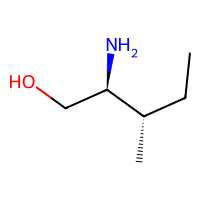
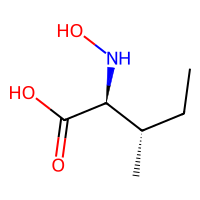
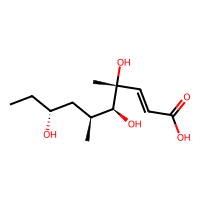
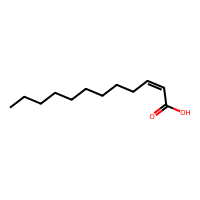
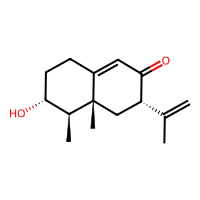
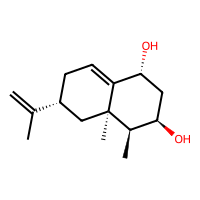
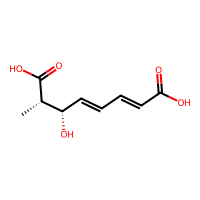
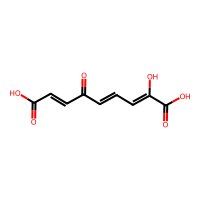
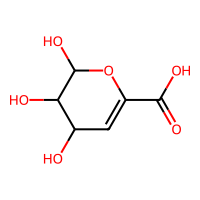
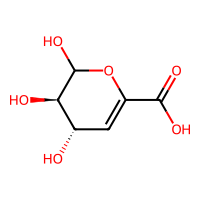
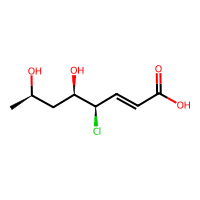
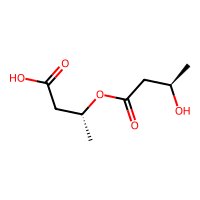
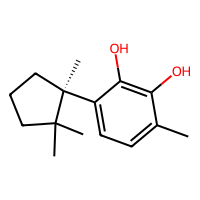
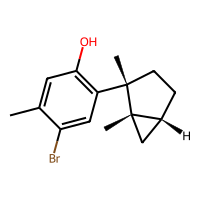
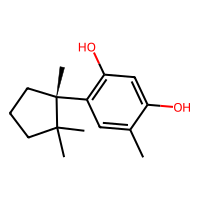
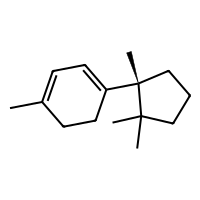
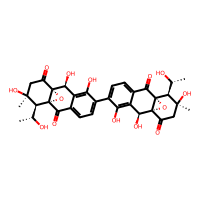
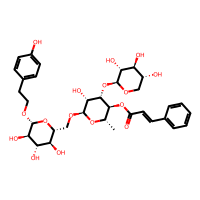
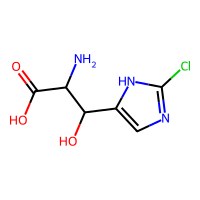
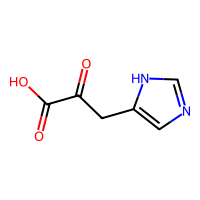

In [ ]:
BUL_fvs = np.stack(df_BUL['Feature_vec'].values)     # stacked feature vectors
BUL_atoms = df_BUL['ATOMS'].values                   # atom counts

results = []

for uul in tqdm(df_UUL.itertuples(index=False), total=len(df_UUL)):
    fv_u = uul.Feature_vec
    num_atoms_u = uul.ATOMS

    # filter BUL candidates by atom count difference
    mask = abs(BUL_atoms - num_atoms_u) <= 5
    fvs_filtered = BUL_fvs[mask]
    bul_subset = df_BUL.loc[mask]

    # compute all probabilities at once
    diffs = np.abs(fvs_filtered - fv_u)
    probs = clf.predict_proba(diffs)[:, 1]

    # most similar candidate
    if len(bul_subset) > 0:
        Similar_idx = np.argmax(probs)
        Similar_row = bul_subset.iloc[Similar_idx]
        results.append([Similar_row.ID, Similar_row.ISOSMILES, probs[Similar_idx]])
    else:
        results.append(['', '', 0])

df_UUL[['KID_Similar', 'ISOSMILES_Similar', 'Prob_Similar']] = results
df_UUL['Prob_Similar'] = pd.to_numeric(df_UUL['Prob_Similar'], errors='coerce')
df_UUL['Prob_Similar'] = df_UUL['Prob_Similar'].round(2)
PandasTools.AddMoleculeColumnToFrame(df_UUL, smilesCol='ISOSMILES_Similar', molCol='ROMol_Similar')
df_UUL['InChI'] = df_UUL['ROMol'].apply(lambda x: Chem.MolToInchi(x))

df_UUL = df_UUL[['UID', 'ISOSMILES', 'InChI', 'ROMol', 'KID_Similar', 'ISOSMILES_Similar', 'ROMol_Similar', 'Prob_Similar']]
df_UUL.drop(columns=['ROMol', 'ROMol_Similar']).to_csv('data/Database_UUL.csv', index=False)
df_UUL.to_pickle('data/Database_UUL.pkl')

df_UUL

In [1]:
df_UUL

NameError: name 'df_UUL' is not defined